C:\Users\kamma\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
C:\Users\kamma\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Train RMSE: 4.519782708765442, Test RMSE: 5.631976878028782
Train R²: 0.8977605470447428, Test R²: 0.7533649285449188


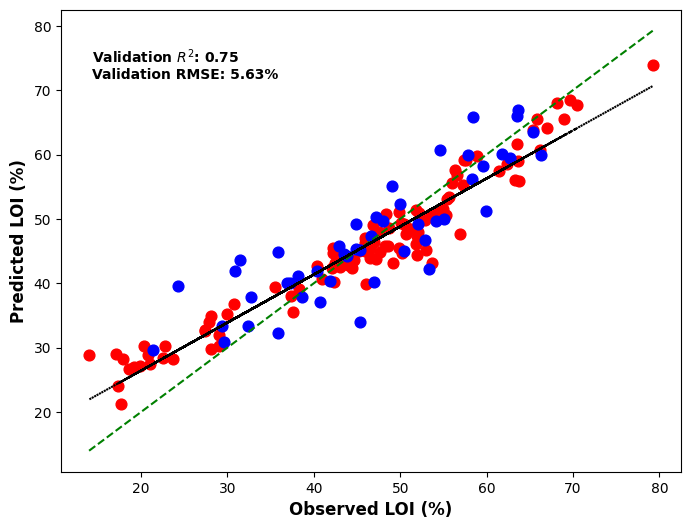

C:\Users\kamma\AppData\Local\Temp\ipykernel_5248\3944208418.py:79: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_yticklabels(importance_df['Feature'], fontsize=10, fontweight='bold')


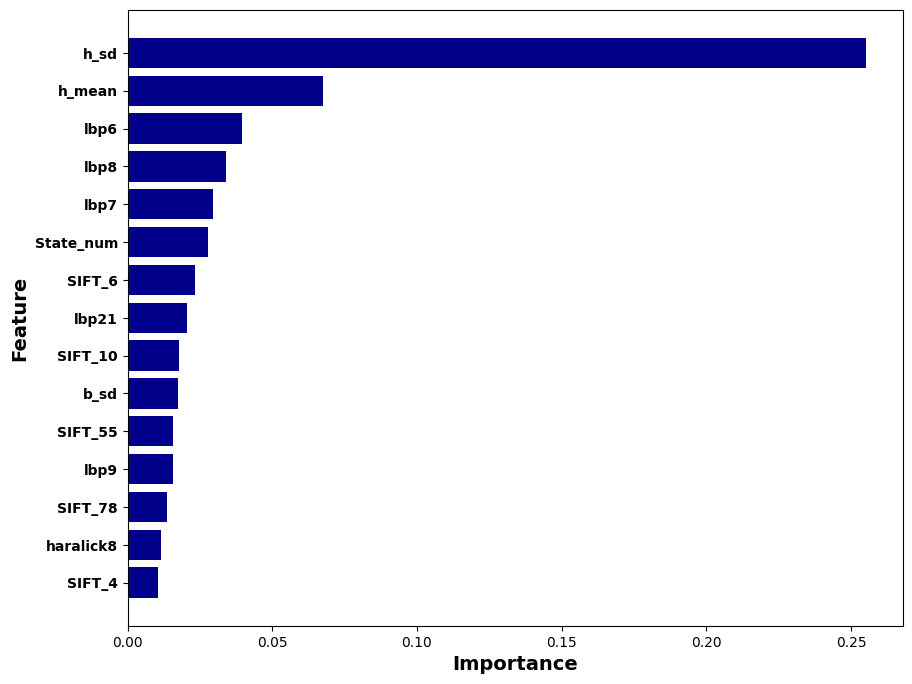

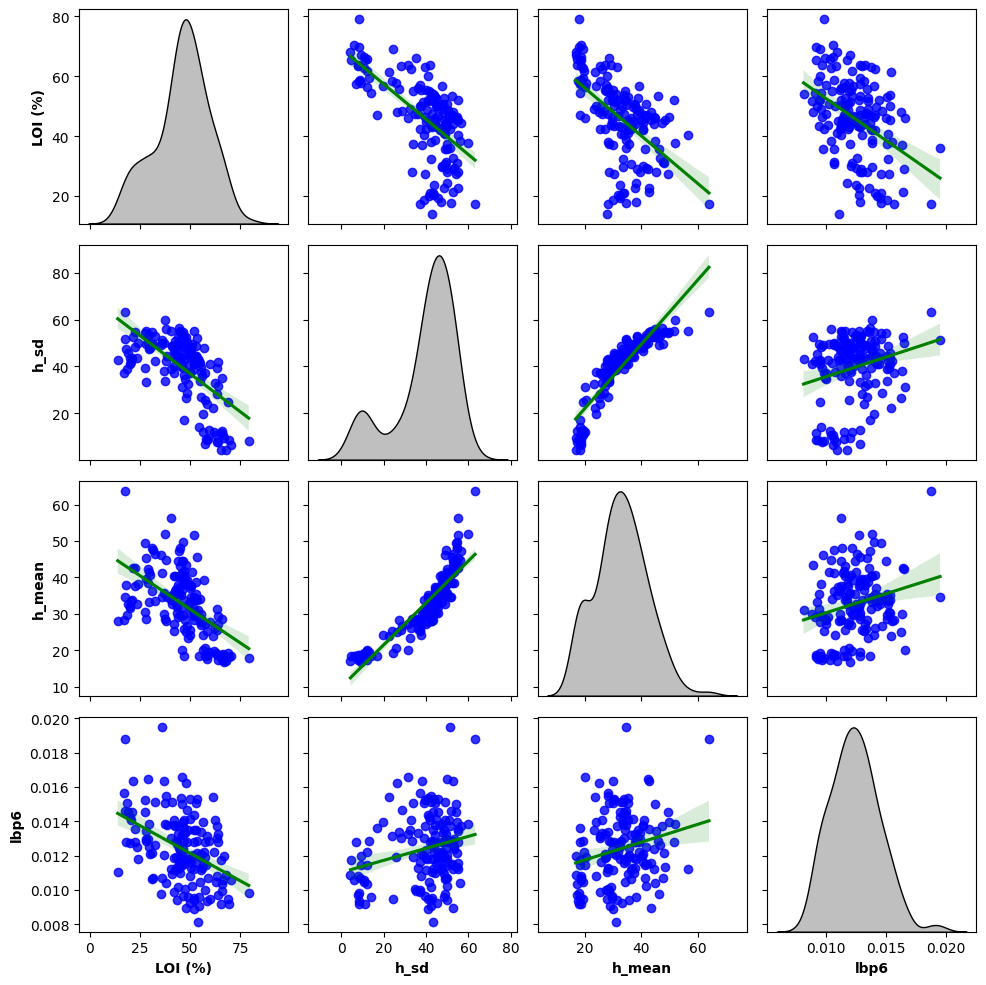

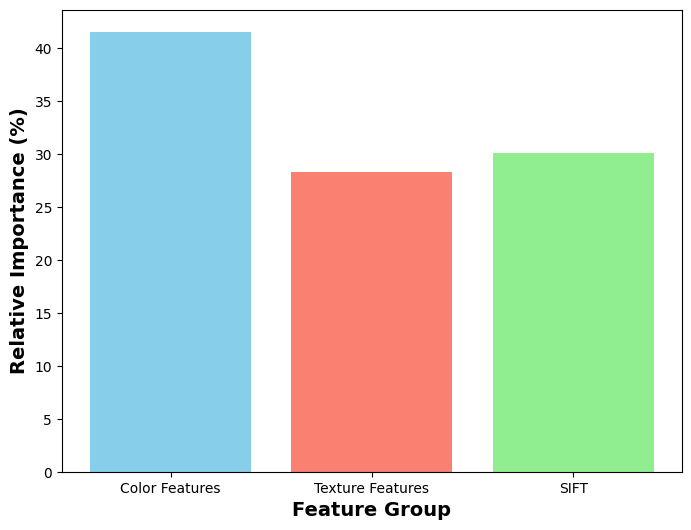

In [2]:
import pandas as pd
import seaborn as sns
data = pd.read_csv("DRY MODEL 1 - DRY MODEL 1.csv")
X = data.drop(columns=['Sample', 'LOI (%)'])
y = data['LOI (%)']
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(n_estimators=150, max_depth=15, random_state=42)
rf_model.fit(X_train, y_train)
from sklearn.metrics import mean_squared_error, r2_score
y_pred_train = rf_model.predict(X_train)
y_pred_test = rf_model.predict(X_test)

train_rmse = mean_squared_error(y_train, y_pred_train, squared=False)
test_rmse = mean_squared_error(y_test, y_pred_test, squared=False)
train_r2 = r2_score(y_train, y_pred_train)
test_r2 = r2_score(y_test, y_pred_test)

print(f"Train RMSE: {train_rmse}, Test RMSE: {test_rmse}")
print(f"Train R²: {train_r2}, Test R²: {test_r2}")
import matplotlib.pyplot as plt
import numpy as np

# Scatter plot of calibration and validation data
plt.figure(figsize=(8, 6))

# Calibration data in red solid dots with larger markers
plt.scatter(y_train, y_pred_train, color='red', alpha=1, s=60)

# Validation data in blue solid dots with larger markers
plt.scatter(y_test, y_pred_test, color='blue', alpha=1, s=60)

min_val = min(y.min(), y_pred_train.min(), y_pred_test.min())
max_val = max(y.max(), y_pred_train.max(), y_pred_test.max())
plt.plot([min_val, max_val], [min_val, max_val], 'g--', linewidth=1.5)

# Calibration regression line in black dots
z_calibration = np.polyfit(y_train, y_pred_train, 1)
p_calibration = np.poly1d(z_calibration)
plt.plot(y_train, p_calibration(y_train), 'k:', linewidth=1.5)

plt.gca().spines['top'].set_visible(True)
plt.gca().spines['right'].set_visible(True)
plt.gca().spines['left'].set_visible(True)
plt.gca().spines['bottom'].set_visible(True)
plt.grid(False)

plt.xlabel("Observed LOI (%)", fontsize=12, fontweight='bold')
plt.ylabel("Predicted LOI (%)", fontsize=12, fontweight='bold')

plt.text(0.05, 0.85, f'Validation $R^2$: {test_r2:.2f}\nValidation RMSE: {test_rmse:.2f}%', 
         transform=plt.gca().transAxes, fontsize=10, fontweight='bold', color='black')

plt.legend(loc="upper left", frameon=False)
plt.show()
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# Extract feature importances from the trained Random Forest model
feature_importances = rf_model.feature_importances_
feature_names = X.columns

# Sort the feature importances in descending order and select the top 15
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False).head(15)

plt.figure(figsize=(10, 8))
plt.barh(importance_df['Feature'], importance_df['Importance'], color='darkblue')
plt.gca().invert_yaxis()  # To have the highest importance feature at the top

plt.xlabel("Importance", fontsize=14, fontweight='bold')
plt.ylabel("Feature", fontsize=14, fontweight='bold')

plt.gca().set_yticklabels(importance_df['Feature'], fontsize=10, fontweight='bold')

plt.gca().spines['top'].set_visible(True)
plt.gca().spines['right'].set_visible(True)
plt.gca().spines['left'].set_visible(True)
plt.gca().spines['bottom'].set_visible(True)
plt.grid(False)

plt.show()
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

# Pair plot of LOI and the top three features: h-sd, h-mean, and lbp6
selected_features = data[['LOI (%)', 'h_sd', 'h_mean', 'lbp6']]

# Pair plot
sns.pairplot(selected_features, kind='reg', diag_kind='kde', plot_kws={'color': 'blue', 'line_kws': {'color': 'green'}}, diag_kws={'color': 'black'})
plt.subplots_adjust(wspace=0.1, hspace=0.1)  # Adjust space between plots

for ax in plt.gcf().axes:
    ax.spines['top'].set_visible(True)
    ax.spines['right'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['bottom'].set_visible(True)
    ax.xaxis.label.set_fontweight('bold')
    ax.yaxis.label.set_fontweight('bold')

plt.show()


# Feature comparison plot
data = pd.read_csv("DRY MODEL 1 - DRY MODEL 1.csv")

# Define merged feature groups 
color_features = [
    'r_mean', 'g_mean', 'b_mean', 'r_median', 'g_median', 'b_median',
    'r_sd', 'g_sd', 'b_sd', 'h_mean', 's_mean', 'v_mean', 
    'h_median', 's_median', 'v_median', 'h_sd', 's_sd', 'v_sd',
    'h0', 'h1', 'h2', 'h3', 'h4', 'h5', 'h6'
]
texture_features = [
    'haralick1', 'haralick2', 'haralick3', 'haralick4', 'haralick5', 
    'haralick6', 'haralick7', 'haralick8', 'haralick9', 'haralick10', 
    'haralick11', 'haralick12', 'haralick13',
    'lbp0', 'lbp1', 'lbp2', 'lbp3', 'lbp4', 'lbp5', 'lbp6', 'lbp7', 'lbp8', 'lbp9',
    'lbp10', 'lbp11', 'lbp12', 'lbp13', 'lbp14', 'lbp15', 'lbp16', 'lbp17', 'lbp18', 
    'lbp19', 'lbp20', 'lbp21', 'lbp22', 'lbp23', 'lbp24', 'lbp25'
]
sift_features = [f'SIFT_{i}' for i in range(100)]  # Adjust the range if there are more SIFT features

# Combine all features into X and set LOI (%) as the target
X = data[color_features + texture_features + sift_features]
y = data['LOI (%)']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Train Random Forest model
rf_model = RandomForestRegressor(n_estimators=150, max_depth=15, random_state=42)
rf_model.fit(X_train, y_train)

# Calculate feature importances
importances = rf_model.feature_importances_

# Sum up importances for each group
color_importance = sum(importances[X.columns.get_loc(f)] for f in color_features)
texture_importance = sum(importances[X.columns.get_loc(f)] for f in texture_features)
sift_importance = sum(importances[X.columns.get_loc(f)] for f in sift_features)

# Calculate relative importances
total_importance = color_importance + texture_importance + sift_importance
relative_importances = [
    (color_importance / total_importance) * 100,
    (texture_importance / total_importance) * 100,
    (sift_importance / total_importance) * 100
]

# Data for plotting
feature_groups = ['Color Features', 'Texture Features', 'SIFT']
importance_data = pd.DataFrame({
    'Feature Group': feature_groups,
    'Relative Importance (%)': relative_importances
})

# Plotting
plt.figure(figsize=(8, 6))
plt.bar(importance_data['Feature Group'], importance_data['Relative Importance (%)'], color=['skyblue', 'salmon', 'lightgreen'])

plt.xlabel("Feature Group", fontsize=14, fontweight='bold')
plt.ylabel("Relative Importance (%)", fontsize=14, fontweight='bold')
plt.gca().spines['top'].set_visible(True)
plt.gca().spines['right'].set_visible(True)
plt.gca().spines['left'].set_visible(True)
plt.gca().spines['bottom'].set_visible(True)
plt.grid(False)

plt.show()
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
